# 0. Regrid observations to the SamudrACE grid

Puts the observational references on the same 1° SamudrACE grid as the `ncremap`-regridded E3SM and SamudrACE hindcasts, using ESP-Lab's conservative regridder (`esp_lab.utils.regrid_utils.make_regridder`, xESMF, periodic). The outputs are then reshaped with the existing `merge_datasets.py` helpers (`load_obs`, `build`, `write`) into the hindcast layout used by `1-nRMSE-ACC.ipynb`.

For each `(product, variable)` this notebook writes two files:

| Output | Layout | Used for |
|---|---|---|
| `obs_regridded/<tag>_<VAR>_samudrace_monthly.nc` | `VAR(time, lat, lon)` | continuous series (e.g. teleconnection regressions) |
| `merged/<tag>_<VAR>_samudrace.nc` | `VAR(start_date, lead, lat, lon)` | verifying obs for every hindcast start and lead |

Values are converted to the units of the merged model files: K for temperatures, m/s for precipitation, Pa for pressure, W m-2 (positive upward) for latent heat flux.

Observation sources live under `/global/cfs/cdirs/e3sm/e3sm_diags/obs_for_e3sm_diags/time-series` (`esp_lab.env_paths.obs_root()`):

| Variable | Product | File | Notes |
|---|---|---|---|
| PRECT | GPCP v2.3 | `GPCP_v2.3/PRECT_197901_201712.nc` | 2.5°, mm/d; ends 2017-12 |
| TS | ERA5 | `ERA5/ts_197901_201912.nc` | land + ocean; ESP-Lab's TS reference |
| TREFHT | ERA5 | `ERA5/tas_197901_201912.nc` | |
| PSL | ERA5 | `ERA5/psl_197901_201912.nc` | Niño 3.4 teleconnections |
| LHFLX | ERA5 | `ERA5/hfls_197901_201912.nc` | land + ocean, positive upward |
| LHFLX | OAFlux | `OAFlux/LHFLX_197901_201312.nc` | ocean only; ends 2013; time stamps are offset, so months are taken from the file period |
| TS | HadISST2 | `HadISST2/ts_186901_202212.nc` | land values are filler; mask land in the analysis |
| SST | HadISST2 | `HadISST2/tos_186901_202212.nc` (variable `sst`) | land/ice filler as above |

A hindcast start is only written when all 24 verifying months are available, so products that end early (GPCP 2017-12, ERA5 2019-12, OAFlux 2013-12) cover fewer starts.

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace
import warnings

ANALYSIS_DIR = Path.cwd()
SAM_DIR = Path("/pscratch/sd/e/edejong/samudrace/hist-2y_runs_v0/analysis")
ESP_LAB_ROOT = Path("/pscratch/sd/e/edejong/ESP-Lab")
for path in (ESP_LAB_ROOT, ANALYSIS_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import merge_datasets as md
from esp_lab import env_paths
from esp_lab.utils import regrid_utils as regrid
from esp_lab.utils.netcdf_utils import atomic_to_netcdf

warnings.filterwarnings("ignore", category=RuntimeWarning)

/global/common/software/e3sm/anaconda_envs/e3smu_1_13_0/pm-cpu/pixi_login/.pixi/envs/default/lib/python3.13/site-packages/properscoring/_crps.py:257: SyntaxWarning: invalid escape sequence '\i'
  CRPS(F, x) = \int_z (F(z) - H(z - x))^2 dz
/global/common/software/e3sm/anaconda_envs/e3smu_1_13_0/pm-cpu/pixi_login/.pixi/envs/default/lib/python3.13/site-packages/properscoring/_brier.py:10: SyntaxWarning: invalid escape sequence '\i'
  The Brier score (BS) scores binary forecasts $k \in \{0, 1\}$,
/global/common/software/e3sm/anaconda_envs/e3smu_1_13_0/pm-cpu/pixi_login/.pixi/envs/default/lib/python3.13/site-packages/properscoring/_brier.py:102: SyntaxWarning: invalid escape sequence '\i'
  CRPS(F, x) = \int_z BS(F(z), H(z - x)) dz


## Configuration

`RUN` selects which `(product, variable)` pairs to process. Existing outputs are skipped unless `OVERWRITE = True`.

In [2]:
OBS_ROOT = env_paths.obs_root()
MERGED_DIR = SAM_DIR / "merged"
MONTHLY_DIR = ANALYSIS_DIR / "obs_regridded"
TARGET_GRID = "samudrace"
GRID_SOURCE = MERGED_DIR / f"samudrace-C0A0-EN00_TS_{TARGET_GRID}.nc"

YEARS = list(range(1980, 2019))     # start years; each has May and November starts
PERIOD = ("1979-01", "2020-12")     # monthly window kept in the regridded series
REGRID_METHOD = "conservative"
NA_THRESHOLD = 0.5                  # target cell is NaN if more than half of its source area is missing
OVERWRITE = False


def to_kelvin(da):
    # HadISST2 ts is stored in K but labelled degC, so decide from the magnitude.
    return da if float(da.isel(time=0).mean()) > 100 else da + 273.15


# time="stamp": month of each time stamp; time="sequence": consecutive months from the first YYYYMM in the file name
OBS_PRODUCTS = {
    ("ERA5", "TS"): dict(path=OBS_ROOT / "ERA5/ts_197901_201912.nc", var="ts", units="K"),
    ("ERA5", "TREFHT"): dict(path=OBS_ROOT / "ERA5/tas_197901_201912.nc", var="tas", units="K"),
    ("ERA5", "PSL"): dict(path=OBS_ROOT / "ERA5/psl_197901_201912.nc", var="psl", units="Pa"),
    ("ERA5", "LHFLX"): dict(path=OBS_ROOT / "ERA5/hfls_197901_201912.nc", var="hfls", units="W m-2"),
    ("GPCP", "PRECT"): dict(path=OBS_ROOT / "GPCP_v2.3/PRECT_197901_201712.nc", var="PRECT", units="m/s",
                            convert=lambda da: md.precipitation_in_m_per_s(da, fallback_units="mm/d")),
    ("OAFlux", "LHFLX"): dict(path=OBS_ROOT / "OAFlux/LHFLX_197901_201312.nc", var="LHFLX", units="W m-2",
                              time="sequence"),
    ("HadISST2", "TS"): dict(path=OBS_ROOT / "HadISST2/ts_186901_202212.nc", var="ts", units="K", convert=to_kelvin),
    ("HadISST2", "SST"): dict(path=OBS_ROOT / "HadISST2/tos_186901_202212.nc", var="sst", units="K", convert=to_kelvin),
}

RUN = [("HadISST2", "SST")] #[("GPCP", "PRECT"), ("HadISST2", "SST")]

## Helpers

In [3]:
def monthly_time(ds, mode, path):
    """First-of-month datetime64 labels for each record."""
    if mode == "stamp":
        return ds["time"].values.astype("datetime64[M]").astype("datetime64[ns]")
    first = path.stem.split("_")[-2]
    start = np.datetime64(f"{first[:4]}-{first[4:6]}", "M")
    return (start + np.arange(ds.sizes["time"])).astype("datetime64[ns]")


def open_monthly(spec):
    ds = xr.open_dataset(spec["path"], chunks={"time": 12})
    da = ds[spec["var"]].assign_coords(time=monthly_time(ds, spec.get("time", "stamp"), spec["path"]))
    da = da.drop_vars([c for c in da.coords if c not in ("time", "lat", "lon")])
    return da.sel(time=slice(*PERIOD))


def regrid_to_target(da, grid):
    regridder = regrid.make_regridder(da.to_dataset(), grid, method=REGRID_METHOD, periodic=True)
    out = regridder(da, skipna=True, na_thres=NA_THRESHOLD, keep_attrs=True)
    # ncremap and xESMF agree on cell centres only to float precision
    return out.assign_coords(lat=grid["lat"], lon=grid["lon"])


def area_mean(da):
    return da.weighted(np.cos(np.deg2rad(da["lat"]))).mean(["lat", "lon"])


def output_paths(product, variable):
    tag = product.lower()
    return (MONTHLY_DIR / f"{tag}_{variable}_{TARGET_GRID}_monthly.nc",
            MERGED_DIR / f"{tag}_{variable}_{TARGET_GRID}.nc")

## Target grid

In [4]:
with xr.open_dataset(GRID_SOURCE) as ds:
    grid = xr.Dataset(coords={"lat": ds["lat"].load(), "lon": ds["lon"].load()})
print(f"Target grid from {GRID_SOURCE.name}: {grid.sizes['lat']} x {grid.sizes['lon']}, "
      f"lat {float(grid.lat[0]):.2f}..{float(grid.lat[-1]):.2f}, lon {float(grid.lon[0]):.2f}..{float(grid.lon[-1]):.2f}")

Target grid from samudrace-C0A0-EN00_TS_samudrace.nc: 180 x 360, lat -89.24..89.24, lon 0.50..359.50


## Regrid and write

The source global mean and the regridded global mean are printed for the first month as a conservation check. ERA5 (0.25°) takes the longest because the regridding weights are built from about 1 million source cells.

In [5]:
regridded = {}
for product, variable in RUN:
    spec = OBS_PRODUCTS[(product, variable)]
    monthly_path, merged_path = output_paths(product, variable)
    print(f"=== {product} {variable}: {spec['path']}")

    if monthly_path.exists() and not OVERWRITE:
        print(f"  reusing {monthly_path}")
        obs = xr.open_dataset(monthly_path)[variable].load()
    else:
        source = open_monthly(spec)
        obs = regrid_to_target(source, grid)
        print(f"  first-month global mean in source units: source {float(area_mean(source.isel(time=0))):.6g}, "
              f"regridded {float(area_mean(obs.isel(time=0))):.6g}")
        convert = spec.get("convert")
        obs = (convert(obs) if convert else obs).astype(np.float32).load().rename(variable)
        obs.attrs.update(units=spec["units"], source_file=str(spec["path"]), source_variable=spec["var"],
                         regridding=f"esp_lab regrid_utils {REGRID_METHOD}, periodic, na_thres={NA_THRESHOLD}")
        atomic_to_netcdf(obs.to_dataset().assign_attrs(title=f"{product} {variable} on the {TARGET_GRID} grid"), monthly_path)
        print(f"  wrote {monthly_path}  ({str(obs.time.values[0])[:7]}..{str(obs.time.values[-1])[:7]})")
    regridded[(product, variable)] = obs

    if merged_path.exists() and not OVERWRITE:
        print(f"  {merged_path.name} exists; set OVERWRITE = True to rebuild it")
        continue
    args = SimpleNamespace(variable=variable, target_grid=TARGET_GRID, years=YEARS)
    ds = md.build(product, lambda y, s: md.load_obs(obs, y, s, grid), args, grid,
                  {"source_file": str(spec["path"])})
    if ds is not None:
        ds[variable].attrs.update(units=spec["units"], source_variable=spec["var"])
        md.write(ds, merged_path, OVERWRITE)

=== HadISST2 SST: /global/cfs/cdirs/e3sm/e3sm_diags/obs_for_e3sm_diags/time-series/HadISST2/tos_186901_202212.nc
  reusing /pscratch/sd/e/edejong/ESP-Lab/samudrace-eval/obs_regridded/hadisst2_SST_samudrace_monthly.nc
  hadisst2_SST_samudrace.nc exists; set OVERWRITE = True to rebuild it


## Quick checks

Global-mean monthly series and one regridded month per product.

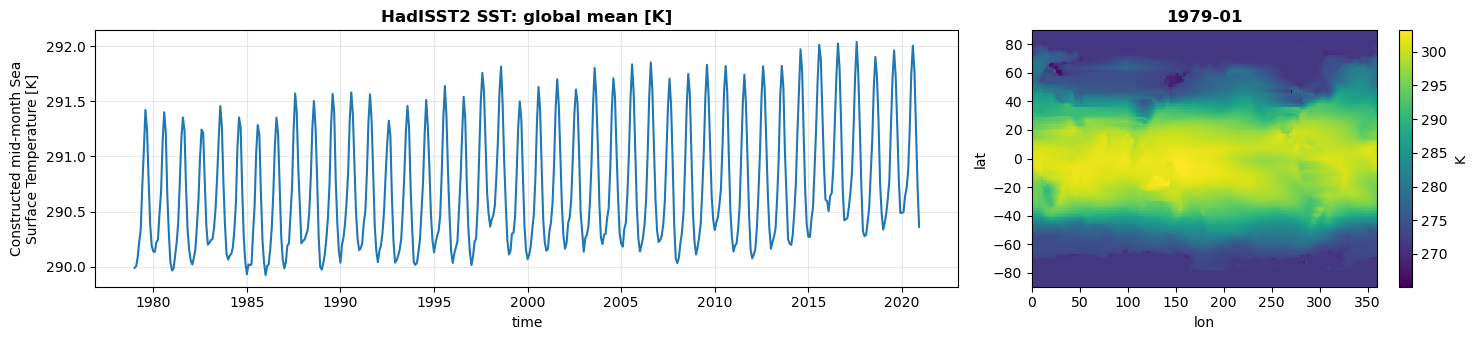

hadisst2_SST_samudrace.nc: {'start_date': 78, 'lead': 24, 'lat': 180, 'lon': 360}, starts 1980-05..2018-11


In [6]:
fig, axes = plt.subplots(len(regridded), 2, figsize=(15, 3.5 * len(regridded)), squeeze=False,
                         gridspec_kw={"width_ratios": [2, 1]})
for row, ((product, variable), obs) in zip(axes, regridded.items()):
    area_mean(obs).plot(ax=row[0])
    row[0].set_title(f"{product} {variable}: global mean [{obs.attrs.get('units', '')}]", fontweight="bold")
    row[0].grid(alpha=0.3)
    obs.isel(time=0).plot(ax=row[1], cbar_kwargs={"label": obs.attrs.get("units", "")})
    row[1].set_title(f"{str(obs.time.values[0])[:7]}", fontweight="bold")
plt.tight_layout()
plt.show()

for product, variable in RUN:
    _, merged_path = output_paths(product, variable)
    if merged_path.exists():
        with xr.open_dataset(merged_path) as ds:
            starts = ds["start_date"].values
            print(f"{merged_path.name}: {dict(ds[variable].sizes)}, starts {str(starts[0])[:7]}..{str(starts[-1])[:7]}")